# 04 · Expression — EMT-transcription-factor overlay

*(Renumbered from 06: with **Gate 2 = NO-GO** the branching-only correlation and modules
notebooks are not produced — this unconditional expression notebook follows signatures directly,
per §6: Gate 2 NO-GO → 01–03 + expression(04).)*

The EMT-TF overlay is produced **regardless of gate outcome**. Puram overlays SNAI1 (root) +
ZEB1 (terminus); per the derive-don't-inherit mandate we do **not** inherit that pair. We score a
candidate panel — canonical Snail/Zeb/Twist **plus** the mesenchymal/neural-crest FOXC and PRRX
families — on *this* dataset, gate on a 3% detection floor, and overlay the thresholded expressers
as a **categorical** overlay on a grey manifold (the reference style — not a continuous single-gene
colormap). **VIM is excluded**: vimentin is a mesenchymal marker, not a transcription factor.
Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted, signature-scored manifold (house linear layout)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out,'signatures.h5ad'))
adata.obsm['X_umap']=adata.obsm['X_umap_lin']
t=adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 5645 | pseudotime range 0.0 -> 10.16


### Derive the end-specific EMT-TFs (data-driven, detection-gated)
For each candidate TF: fraction expressing, mean expression in the early (root) vs late (terminus)
pseudotime tercile, and Spearman correlation with pseudotime. Factors below a 3% expression floor
are too sparse to overlay. The most negative rho (among expressed) marks the root end; the most
positive marks the terminus.

In [4]:
panel=['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']  # VIM excluded (not a TF)
raw=adata.raw.to_adata() if adata.raw is not None else adata
present=[g for g in panel if g in raw.var_names]
early=tn<=np.quantile(tn,1/3); late=tn>=np.quantile(tn,2/3)
X=raw[:,present].X; X=X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x=X[:,j]; rho,_=spearmanr(tn,x)
    rows.append((g,round((x>0).mean(),3),round(x[early].mean(),3),round(x[late].mean(),3),round(rho,3)))
df=pd.DataFrame(rows,columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end']=np.where(df.mean_early>df.mean_late,'EARLY(root)','LATE(terminus)')
df=df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok=df[df.frac_expr>0.03]
print('\nabove 3% detection floor:', ok.TF.tolist())
early_tf=ok.sort_values('rho_vs_t').iloc[0]['TF']; late_tf=ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'derived pair: {early_tf} (relatively earlier) <-> {late_tf} (most terminal)')
print('NOTE: in this FL dataset only ZEB1/ZEB2 clear detection and BOTH are terminus-loaded;')
print('no root-loaded EMT-TF is detectable, so the shown pair spans the observed trend rather than an early-vs-late split.')

   TF  frac_expr  mean_early  mean_late  rho_vs_t            end
SNAI1      0.003       0.003      0.001    -0.037    EARLY(root)
FOXC1      0.004       0.004      0.003    -0.014    EARLY(root)
 ZEB2      0.272       0.233      0.271     0.018 LATE(terminus)
SNAI2      0.002       0.001      0.002     0.018 LATE(terminus)
 ZEB1      0.121       0.051      0.094     0.106 LATE(terminus)

above 3% detection floor: ['ZEB2', 'ZEB1']
derived pair: ZEB2 (relatively earlier) <-> ZEB1 (most terminal)
NOTE: in this FL dataset only ZEB1/ZEB2 clear detection and BOTH are terminus-loaded;
no root-loaded EMT-TF is detectable, so the shown pair spans the observed trend rather than an early-vs-late split.


### EMT-TF expression overlay (deliverable) — reference categorical style
`figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Thresholded expressers overlaid as solid
categorical colours on a grey manifold; the more widely-expressed factor drawn first, the sparser
on top, so neither is occluded. Display cutoff = upper quartile among expressing cells (so the
scale is not outlier-washed).

overlay thresholds (upper quartile among expressers): {'ZEB2': 1.2, 'ZEB1': 0.764}
ZEB2: 27.2% expressing; 384 shown; mean pseudotime shown = 0.49
ZEB1: 12.1% expressing; 171 shown; mean pseudotime shown = 0.47
saved expression.pdf


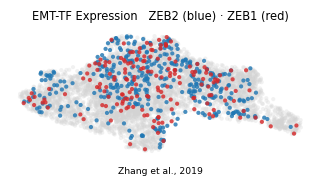

In [5]:
def _vec(g):
    x=raw[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
xl=adata.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
thr={}
for g in [early_tf,late_tf]:
    v=_vec(g); pos=v[v>0]; thr[g]=float(np.quantile(pos,0.75)) if pos.size else 0.0
sel={g:_vec(g)>thr[g] for g in [early_tf,late_tf]}
order=sorted([early_tf,late_tf],key=lambda g:-int(sel[g].sum()))
colors={early_tf:'tab:blue',late_tf:'tab:red'}
fig,ax=plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata,size=30,alpha=.3,frameon=False,show=False,ax=ax,na_color='lightgray')
for g in order:
    ap=adata[sel[g]].copy()
    sc.pl.umap(ap,na_color=colors[g],size=30,alpha=.8,frameon=False,show=False,ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (blue) · {late_tf} (red)',size=7.5)
ax.text(.5,-.14,'Zhang et al., 2019',ha='center',transform=ax.transAxes,size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'),bbox_inches='tight')
plt.show()
print('overlay thresholds (upper quartile among expressers):',{g:round(thr[g],3) for g in [early_tf,late_tf]})
for g in [early_tf,late_tf]:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown; mean pseudotime shown = {tn[sel[g]].mean():.2f}')
print('saved expression.pdf')